# Practical Tutorial: Ridge Regression (L2 Regularization)

As a future-proof AI/ML engineer, understanding regularization is crucial. Regularization techniques prevent models from overfitting, especially when working with highly collinear features or datasets where the number of features is close to or greater than the number of observations.

### What is Ridge Regression?
Ridge Regression is a variant of linear regression that adds a penalty term to the loss function. The penalty is proportional to the **square of the magnitude of the coefficients** (known as $L_2$ regularization).

**Loss Function:**
$$\text{Loss} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p} w_j^2$$

- $\alpha$ (alpha) is the regularization strength (hyperparameter).
- When $\alpha = 0$, Ridge Regression behaves exactly like Ordinary Least Squares (OLS) Linear Regression.
- As $\alpha \to \infty$, the coefficients ($w_j$) shrink closer to zero, but never reach exactly zero.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# Set seed for reproducibility
np.random.seed(42)

## 1. Generate Synthetic Collinear Data
We will create a dataset with multicollinearity (highly correlated features), which is a classic scenario where OLS Linear Regression fails or becomes highly unstable, while Ridge Regression shines.

In [2]:
# Generate synthetic dataset
n_samples = 150
x = np.random.uniform(-3, 3, size=(n_samples, 1))

# Generate output with some noise
y = 2.5 * x**2 + 0.9 * x + np.random.normal(0, 2, size=(n_samples, 1))
y = y.ravel()

# Create polynomial features manually to introduce collinearity
X = np.hstack([x, x**2, x**3, x**4, x**5])

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardize features (Crucial for Ridge Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train shape: {X_train_scaled.shape}, Test shape: {X_test_scaled.shape}")

Train shape: (105, 5), Test shape: (45, 5)


## 2. Fit Ordinary Linear Regression vs. Ridge Regression

In [3]:
# Train standard OLS Linear Regression
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)

# Train Ridge Regression with alpha = 10
ridge_model = Ridge(alpha=10.0)
ridge_model.fit(X_train_scaled, y_train)

# Predictions
ols_train_pred = ols_model.predict(X_train_scaled)
ols_test_pred = ols_model.predict(X_test_scaled)

ridge_train_pred = ridge_model.predict(X_train_scaled)
ridge_test_pred = ridge_model.predict(X_test_scaled)

# Print metrics
print("--- Ordinary Least Squares (OLS) ---")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, ols_train_pred)):.4f}")
print(f"Test RMSE:  {np.sqrt(mean_squared_error(y_test, ols_test_pred)):.4f}")
print(f"Coefficients: {ols_model.coef_}\n")

print("--- Ridge Regression (Alpha = 10) ---")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, ridge_train_pred)):.4f}")
print(f"Test RMSE:  {np.sqrt(mean_squared_error(y_test, ridge_test_pred)):.4f}")
print(f"Coefficients: {ridge_model.coef_}")

--- Ordinary Least Squares (OLS) ---
Train RMSE: 2.0739
Test RMSE:  1.8648
Coefficients: [ 0.39070684  5.56411962  2.57287269  1.06282235 -1.31325407]

--- Ridge Regression (Alpha = 10) ---
Train RMSE: 2.1512
Test RMSE:  1.8276
Coefficients: [0.87110791 3.81316957 0.57405287 2.51045846 0.22195196]


Notice how OLS has extremely large, fluctuating coefficients, whereas the Ridge model has much smaller, more stable coefficients, leading to a lower test error (preventing overfitting).

## 3. Visualize the Impact of Alpha (Regularization Strength)
Let's trace how coefficients shrink and how generalization performance changes as we increase the regularization strength.

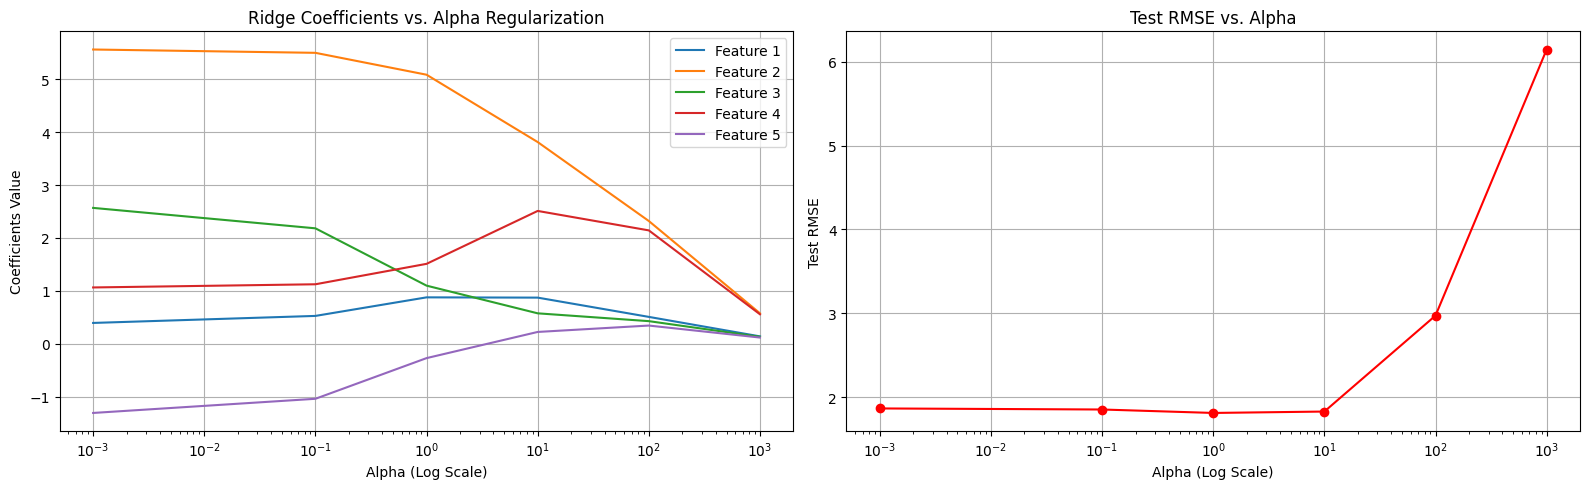

In [4]:
alphas = [0.001, 0.1, 1.0, 10.0, 100.0, 1000.0]
coefs = []
test_rmses = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_scaled, y_train)
    coefs.append(ridge.coef_)
    test_rmses.append(np.sqrt(mean_squared_error(y_test, ridge.predict(X_test_scaled))))

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot coefficients shrinkage
ax1.plot(alphas, coefs)
ax1.set_xscale('log')
ax1.set_xlabel('Alpha (Log Scale)')
ax1.set_ylabel('Coefficients Value')
ax1.set_title('Ridge Coefficients vs. Alpha Regularization')
ax1.grid(True)
ax1.legend([f'Feature {i+1}' for i in range(X.shape[1])])

# Plot Test RMSE profile
ax2.plot(alphas, test_rmses, marker='o', color='r')
ax2.set_xscale('log')
ax2.set_xlabel('Alpha (Log Scale)')
ax2.set_ylabel('Test RMSE')
ax2.set_title('Test RMSE vs. Alpha')
ax2.grid(True)

plt.tight_layout()
plt.show()

## 4. Hyperparameter Tuning with GridSearchCV

In real-world applications, manually picking $\alpha$ is impractical. Instead, we use cross-validation over a logarithmic space. Let's find the mathematically optimal $\alpha$ using Scikit-Learn's `GridSearchCV`.

In [5]:
from sklearn.model_selection import GridSearchCV

# Define a logarithmic range of alphas
param_grid = {'alpha': np.logspace(-3, 3, 13)}

# Instantiate Ridge model
ridge = Ridge()

# Perform 5-fold cross-validation
grid_search = GridSearchCV(estimator=ridge, param_grid=param_grid, scoring='neg_mean_squared_error', cv=5)
grid_search.fit(X_train_scaled, y_train)

# Extract best alpha and estimator
best_alpha = grid_search.best_params_['alpha']
best_ridge_model = grid_search.best_estimator_

print(f"Optimal alpha selected via 5-Fold CV: {best_alpha:.4f}")

Optimal alpha selected via 5-Fold CV: 1.0000


## 5. Comparative Evaluation: RMSE & R²

Now, let's compare standard Ordinary Least Squares (OLS) with our tuned Ridge model on both Root Mean Squared Error (RMSE) and the Coefficient of Determination ($R^2$).

In [6]:
# Best Ridge predictions
best_ridge_train_pred = best_ridge_model.predict(X_train_scaled)
best_ridge_test_pred = best_ridge_model.predict(X_test_scaled)

# Evaluate metrics
ols_test_rmse = np.sqrt(mean_squared_error(y_test, ols_test_pred))
ridge_test_rmse = np.sqrt(mean_squared_error(y_test, best_ridge_test_pred))

ols_test_r2 = r2_score(y_test, ols_test_pred)
ridge_test_r2 = r2_score(y_test, best_ridge_test_pred)

metrics_df = pd.DataFrame({
    'Metric': ['Test RMSE', 'Test R² Score'],
    'OLS Linear Regression': [ols_test_rmse, ols_test_r2],
    'Tuned Ridge Regression': [ridge_test_rmse, ridge_test_r2]
})

display(metrics_df)

,Metric,OLS Linear Regression,Tuned Ridge Regression
0,Test RMSE,1.864761,1.810803
1,Test R² Score,0.934014,0.937778


## 7. Additional Coding Practice

### Task 1: Record Slope Coefficients for $\lambda$ (Alpha) = 0, 1, 10, and 100
Let's extract and compare the fitted coefficients (slopes) for different penalty strengths.

In [7]:
lambda_values = [0, 1, 10, 100]
slopes_record = {}

for lam in lambda_values:
    # alpha=0 in Ridge is equivalent to standard OLS Linear Regression
    if lam == 0:
        model = LinearRegression()
    else:
        model = Ridge(alpha=lam)

    model.fit(X_train_scaled, y_train)
    slopes_record[f"Lambda = {lam}"] = model.coef_

slopes_df = pd.DataFrame(slopes_record, index=[f"Feature {i+1} Slope" for i in range(X_train_scaled.shape[1])])
display(slopes_df)

,Lambda = 0,Lambda = 1,Lambda = 10,Lambda = 100
Feature 1 Slope,0.390707,0.876099,0.871108,0.506777
Feature 2 Slope,5.564120,5.086669,3.813170,2.319893
Feature 3 Slope,2.572873,1.097853,0.574053,0.426238
Feature 4 Slope,1.062822,1.509864,2.510458,2.142630
Feature 5 Slope,-1.313254,-0.272954,0.221952,0.342904


### Task 2: Apply Ridge to Polynomial Features (Degrees 1, 2, 3, 5) Using Cross-Validation
We will evaluate different feature spaces to see which polynomial representation generalizes best when paired with L2 regularization.

In [9]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

degrees = [1, 2, 3, 5]
degree_scores = {}

for deg in degrees:
    # Create a pipeline consisting of polynomial mapping, scaling, and Ridge regression
    pipeline = Pipeline([
        ('poly', PolynomialFeatures(degree=deg, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge(alpha=1.0))
    ])

    # Evaluate using 5-Fold cross-validation (negative mean squared error)
    scores = cross_val_score(pipeline, x, y, scoring='neg_mean_squared_error', cv=5)
    rmse_scores = np.sqrt(-scores)
    degree_scores[f"Degree {deg}"] = {
        "CV Mean RMSE": np.mean(rmse_scores),
        "CV Std RMSE": np.std(rmse_scores)
    }

deg_perf_df = pd.DataFrame(degree_scores).T
display(deg_perf_df)

,CV Mean RMSE,CV Std RMSE
Degree 1,7.080681,0.712921
Degree 2,2.080547,0.282368
Degree 3,2.085761,0.279280
Degree 5,2.049642,0.303600


## 6. Analytical Summary

### Why the smallest training error is not necessarily the best model for unseen data:
During training, OLS adjusts its coefficients to fit every quirk, fluctuation, and random noise present in the training set (high variance/overfitting). This yields a remarkably low **Training Error**.

However, when presented with **unseen (test) data**, this noise is absent or different. Because the OLS coefficients are highly sensitive and over-tuned, the model generalizes poorly. By introducing a constraint penalty ($\|w\|_2^2$), Ridge Regression slightly increases training bias to dramatically lower model variance, delivering a model that generalizes robustly to real-world data.